In [14]:
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_rows', None)

In [2]:
df = pd.read_csv("../data/clean/trials.csv")
df.head(10)

,nct_id,title,status,start_date,phase,conditions,sponsor,enrollment,drug,start_year
0,NCT05564104,A Research Study Looking at How a Single Dose ...,COMPLETED,2023-04-05,PHASE1,Hepatic Impairment; Healthy Volunteers,Novo Nordisk A/S,32.0,cagrilintide,2023.0
1,NCT07597018,A Research Study to Compare Blood Levels of Ca...,RECRUITING,2026-05-18,PHASE1,Obesity; Overweight,Novo Nordisk A/S,234.0,cagrilintide,2026.0
2,NCT06323161,A Research Study to See How Much CagriSema Low...,COMPLETED,2024-03-26,PHASE3,Type 2 Diabetes,Novo Nordisk A/S,274.0,cagrilintide,2024.0
3,NCT07220759,Weight Loss in People Living With Overweight o...,ACTIVE_NOT_RECRUITING,2025-11-05,PHASE3,Overweight; Obesity; Type 2 Diabetes,Novo Nordisk A/S,330.0,cagrilintide,2025.0
4,NCT07357766,A Research Study to Compare Different Versions...,WITHDRAWN,2026-06-22,PHASE3,Overweight; Obesity,Novo Nordisk A/S,0.0,cagrilintide,2026.0
5,NCT07010432,The Role of the Amylin Analogue Cagrilintide i...,RECRUITING,2025-06-12,PHASE1,Obesity,Novo Nordisk A/S,144.0,cagrilintide,2025.0
6,NCT05669755,REDEFINE 3: A Research Study to See the Effect...,ACTIVE_NOT_RECRUITING,2023-03-01,PHASE3,Cardiovascular Disease,Novo Nordisk A/S,7101.0,cagrilintide,2023.0
7,NCT06065540,A Research Study to See How Well CagriSema Com...,COMPLETED,2023-09-27,PHASE3,Type 2 Diabetes Mellitus,Novo Nordisk A/S,2734.0,cagrilintide,2023.0
8,NCT06797869,A Research Study to Investigate the Effects of...,COMPLETED,2025-01-29,PHASE2,"Diabetes Mellitus, Type 2; Diabetic Peripheral...",Novo Nordisk A/S,142.0,cagrilintide,2025.0
9,NCT06267092,A Study of How CagriSema Works on Appetite in ...,COMPLETED,2024-02-15,PHASE1,Overweight; Obesity,Novo Nordisk A/S,164.0,cagrilintide,2024.0


In [15]:
df.isna().sum()

nct_id          0
title           0
status          0
start_date      2
phase         317
conditions      0
sponsor         0
enrollment      1
drug            0
start_year      2
dtype: int64

In [23]:
print(df['start_year'].unique().tolist())

[2023.0, 2026.0, 2024.0, 2025.0, 2022.0, 2021.0, 2020.0, 2017.0, 2016.0, 2019.0, nan, 2018.0, 2013.0, 2014.0, 2015.0, 2027.0, 2008.0, 2028.0, 2012.0, 2009.0, 2011.0, 2007.0]


Видно что у части строк дата есть, а года нет. Это надо исправить для дальнейшего анализа.

In [11]:
df["start_year"] = pd.to_numeric(df["start_date"].str[:4], errors="coerce")
df.isna().sum()

nct_id          0
title           0
status          0
start_date      2
phase         317
conditions      0
sponsor         0
enrollment      1
drug            0
start_year      2
dtype: int64

In [8]:
df["status"].value_counts()

status
COMPLETED                  558
RECRUITING                 311
NOT_YET_RECRUITING         190
ACTIVE_NOT_RECRUITING      140
UNKNOWN                     48
ENROLLING_BY_INVITATION     23
WITHDRAWN                   22
TERMINATED                  10
AVAILABLE                    1
SUSPENDED                    1
Name: count, dtype: int64

Есть исследование со статусом WITHDRAWN и enrollment 0 (NCT07357766). Оно было заявлено, но не началось. Решено исключить WITHDRAWN из подсчёта активности.

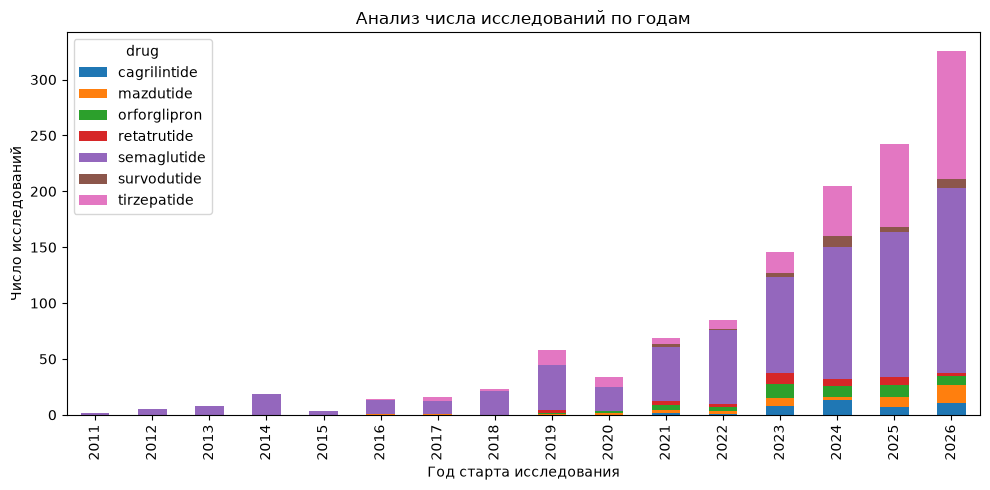

In [28]:
d = df[df["status"] != "WITHDRAWN"].dropna(subset=["start_year"]).copy()
d["start_year"] = d["start_year"].astype(int)
d = d[(d["start_year"] >= 2010) & (d["start_year"] <= 2026)]
len(d)


by_year = pd.crosstab(d["start_year"], d["drug"])
by_year


by_year.plot(kind="bar", stacked=True, figsize=(10, 5))
plt.title("Анализ числа исследований по годам")
plt.xlabel("Год старта исследования")
plt.ylabel("Число исследований")
plt.tight_layout()
plt.savefig("../figures/01_trials_by_year.png", dpi=200, bbox_inches="tight")
plt.show()

Большая часть исследований появились уже с 2021 года, хоть и в 2019 был небольшой скачок, в основном за счёт добавления исследований по другим препаратам. До 2019 исследований не по Semaglutide практически не было, большая часть исследований за всё время именно по Semaglutide и Tirzepatide. 

In [30]:
total = len(d)
print((d["start_year"] >= 2021).sum() / total)           # доля исследований с 2021 года
print(d["drug"].value_counts(normalize=True))             # доля препаратов

0.8549800796812749
drug
semaglutide     0.604781
tirzepatide     0.235857
orforglipron    0.042231
mazdutide       0.035060
cagrilintide    0.033466
retatrutide     0.025498
survodutide     0.023108
Name: proportion, dtype: float64


Итог: около 85% исследований стартовали с 2021 года. Semaglutide (60,5%) и tirzepatide (23,6%) вместе дают около 84% всей активности. Новые молекулы (orforglipron, mazdutide, retatrutide, survodutide) и cagrilintide вместе составляют около 16%.

### Но в каких именно областях растёт применение антагонистов GLP-1/GIP/GCGR?

In [47]:
cats = {
    "diabetes": ["diabet"],
    "obesity": ["obes", "overweight", "weight"],
    "liver": ["nash", "mash", "steatohep", "liver", "hepat"],
    "cardio": ["cardio", "heart", "hypertens"],
    "kidney": ["kidney", "renal", "nephro"],
    "healthy": ['healthy']
}
low = d["conditions"].str.lower()
for k, words in cats.items():
    d[k] = low.str.contains("|".join(words), na=False)
d["other"] = ~d[list(cats)].any(axis=1)

In [48]:
cols = list(cats) + ["other"]
print(d[cols].sum().sort_values(ascending=False))
print()
print(d[d["other"]]["conditions"].str.split("; ").explode().value_counts().head(20))
print()
print(len(d))

obesity     616
diabetes    509
other       145
healthy      93
cardio       79
liver        62
kidney       49
dtype: int64

conditions
Alcohol Use Disorder                       9
Endometrial Cancer                         4
Gastric Retention                          4
Endometrioid Endometrial Adenocarcinoma    3
Metabolic Syndrome                         3
Semaglutide                                3
Opioid Use Disorder                        3
Acute Ischemic Stroke                      3
T2DM                                       3
Alcohol Use Disorder (AUD)                 3
Polycystic Ovary Syndrome                  2
Alzheimer Disease                          2
GLP-1                                      2
Aging                                      2
Semaglutide-Induced Gastric Motility       2
Anesthesia                                 2
Psoriasis                                  2
Caloric Restriction                        2
Body Composition                           2
Performa

Ожирение и диабет занимают основу исследований, а кардио, печень и почки пока составляют небольшую долю.

Сумма больше 1255 (1494), потому что одно исследование может быть сразу в двух категориях, например в диабете и ожирении.

In [49]:
by_cat_year = d.groupby("start_year")[cols].sum()
by_cat_year.loc[2018:]

by_cat_drug = d.groupby("drug")[cols].sum()
by_cat_drug

,diabetes,obesity,liver,cardio,kidney,healthy,other
drug,,,,,,,
cagrilintide,14,29,2,1,1,1,0
mazdutide,13,24,5,4,2,2,2
orforglipron,16,23,1,6,3,17,4
retatrutide,10,16,2,2,2,6,0
semaglutide,369,320,35,42,33,48,99
survodutide,2,19,6,0,2,9,0
tirzepatide,85,185,11,24,6,10,40


In [50]:
by_cat_drug.div(d.groupby("drug").size(), axis=0).round(2)

cols = list(cats) + ["other"]
counts = d.groupby("drug")[cols].sum()
share = counts.div(d.groupby("drug").size(), axis=0)
share = share.loc[d["drug"].value_counts().index]
print(share.round(2))

              diabetes  obesity  liver  cardio  kidney  healthy  other
drug                                                                  
semaglutide       0.49     0.42   0.05    0.06    0.04     0.06   0.13
tirzepatide       0.29     0.62   0.04    0.08    0.02     0.03   0.14
orforglipron      0.30     0.43   0.02    0.11    0.06     0.32   0.08
mazdutide         0.30     0.55   0.11    0.09    0.05     0.05   0.05
cagrilintide      0.33     0.69   0.05    0.02    0.02     0.02   0.00
retatrutide       0.31     0.50   0.06    0.06    0.06     0.19   0.00
survodutide       0.07     0.66   0.21    0.00    0.07     0.31   0.00


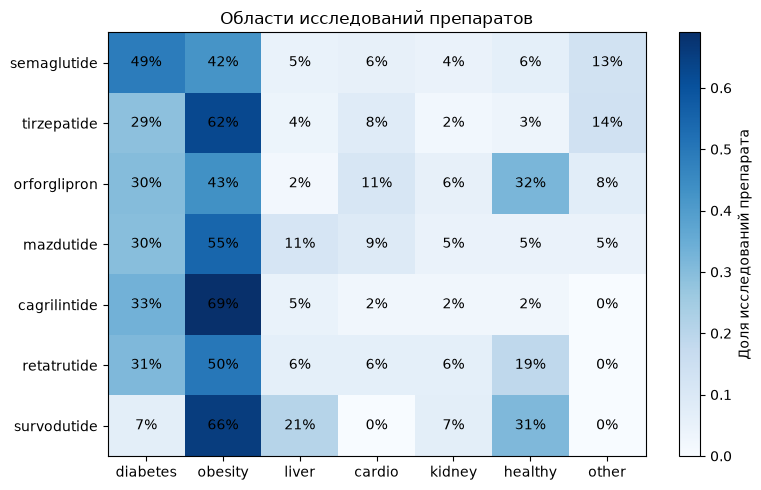

In [64]:
fig, ax = plt.subplots(figsize=(8, 5))
im = ax.imshow(share.values, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(share.columns)))
ax.set_xticklabels(share.columns)
ax.set_yticks(range(len(share.index)))
ax.set_yticklabels(share.index)
for i in range(share.shape[0]):
    for j in range(share.shape[1]):
        ax.text(j, i, f"{share.iloc[i, j]:.0%}", ha="center", va="center")
fig.colorbar(im, label="Доля исследований препарата")
ax.set_title("Области исследований препаратов")  # вывод, а не описание
plt.tight_layout()
plt.savefig("../figures/03_indication_profile.png", dpi=200, bbox_inches="tight")
plt.show()

В профилях показаний доминирует ожирение: у tirzepatide (62%), cagrilintide (69%) и survodutide (66%) оно занимает больше половины исследований. Semaglutide остаётся единственным препаратом с перевесом диабета (49% против 42%). 

Печень заметна у survodutide (21%) и mazdutide (11%), у других не выше 6%. Survodutide выделяется печёночным направлением: 6 исследований (21%), из которых 5 посвящены MASH/NASH и 4 уже находятся в фазе 3. У остальных препаратов печень занимает не более 11%. Это единственный из семи препаратов с такой выраженной специализацией в печени.

Кардио максимально у orforglipron (11%) и mazdutide (9%), почки не выше 7%. 

У orforglipron (32%), survodutide (31%) и retatrutide (19%) велика доля исследований на здоровых добровольцах, что говорит о ранней стадии разработки.

> * Категории пересекаются, одно исследование может быть и в диабете, и в ожирении, поэтому строки в сумме дают больше 100%.

In [52]:
print(d[(d["drug"] == "survodutide") & d["liver"]][["title", "conditions", "phase"]])

                                                 title  \
967  A Study to (1) Compare How BI 456906 is Taken ...   
973  LIVERAGE™: A Study to Test Whether Survodutide...   
977  ELEVATE-LIVER: A Study to Test Whether Survodu...   
987  A Study to Test Safety and Efficacy of Survodu...   
990  LIVERAGE™ - Cirrhosis: A Study to Test Whether...   
991  A Study to Test Whether Survodutide Helps Peop...   

                                            conditions   phase  
967                   Healthy; Liver Diseases; Obesity  PHASE1  
973  Metabolic Dysfunction Associated Steatohepatit...  PHASE3  
977  Obesity; Metabolic Dysfunction-associated Stea...  PHASE3  
987               Non-alcoholic Steatohepatitis (NASH)  PHASE2  
990   Metabolic Dysfunction Associated Steatohepatitis  PHASE3  
991      Obesity; Non-Alcoholic SteatoHepatitis (NASH)  PHASE3  


### Далее следует оценить динамику показаний по годам, чтобы понять, растёт ли количество исследований по печени и кардио:


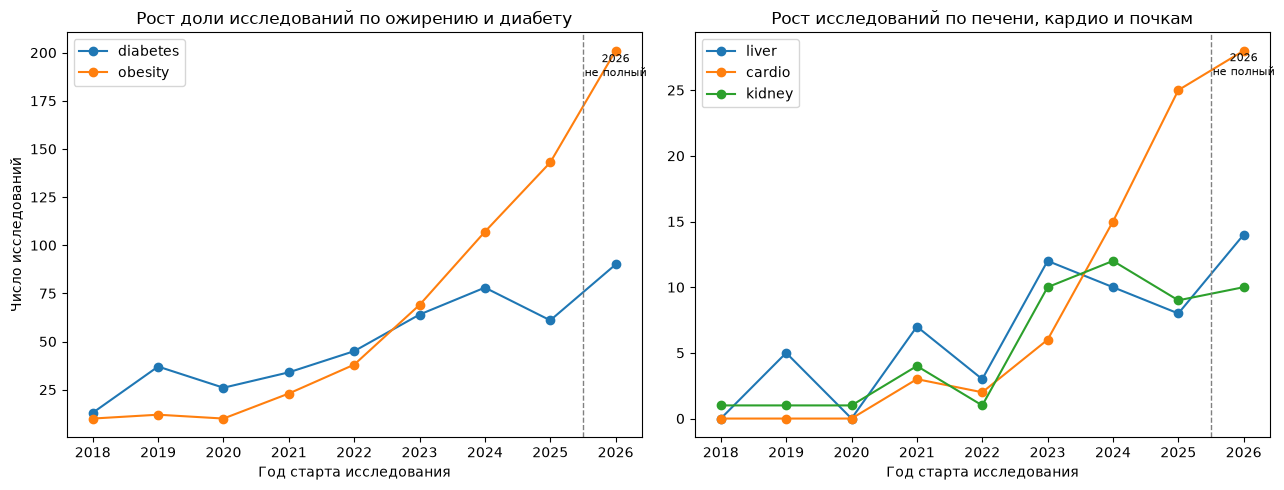

In [63]:
cols = list(cats)  # diabetes, obesity, liver, cardio, kidney, healthy
cat_year = d.groupby("start_year")[cols].sum().loc[2018:]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))

main = ["diabetes", "obesity"]
for c in main:
    axes[0].plot(cat_year.index, cat_year[c], marker="o", label=c)
axes[0].set_title("Рост доли исследований по ожирению и диабету")  # вывод по диабету и ожирению
axes[0].set_xlabel("Год старта исследования")
axes[0].set_ylabel("Число исследований")
axes[0].legend()

small = ["liver", "cardio", "kidney"]
for c in small:
    axes[1].plot(cat_year.index, cat_year[c], marker="o", label=c)
axes[1].set_title("Рост исследований по печени, кардио и почкам")  # вывод по печени, кардио, почкам
axes[1].set_xlabel("Год старта исследования")
axes[1].legend()

for ax in axes:
    ax.axvline(2025.5, color="gray", linestyle="--", linewidth=1)
    ax.text(2026, ax.get_ylim()[1] * 0.95, "2026\nне полный", ha="center", va="top", fontsize=8)

plt.tight_layout()
plt.savefig("../figures/02_indications_by_year.png", dpi=200, bbox_inches="tight")
plt.show()

In [55]:
tot = d.groupby("start_year").size().loc[2018:]
share_year = cat_year.div(tot, axis=0)
print(share_year[["obesity", "cardio", "liver", "kidney"]].round(2))

            obesity  cardio  liver  kidney
start_year                                
2018           0.43    0.00   0.00    0.04
2019           0.21    0.00   0.09    0.02
2020           0.29    0.00   0.00    0.03
2021           0.33    0.04   0.10    0.06
2022           0.45    0.02   0.04    0.01
2023           0.47    0.04   0.08    0.07
2024           0.52    0.07   0.05    0.06
2025           0.59    0.10   0.03    0.04
2026           0.62    0.09   0.04    0.03


In [56]:
print((d["cardio"] & d["obesity"]).sum(), d["cardio"].sum())

40 79


По видимому, 40 из 79 исследований по кардио (около 51%) относятся и к ожирению. Значит, примерно половина кардио-активности возникает внутри ожирения, а вторая половина идёт отдельно (например, в диабете или при болезнях сердца без акцента на вес).

In [62]:
d["phase_max"] = (
    d["phase"].str.findall(r"PHASE(\d)")
    .apply(lambda x: max(x) if isinstance(x, list) and x else None)
)
tab = pd.crosstab(d["drug"], d["phase_max"], normalize="index").round(2)
n = d.dropna(subset=["phase_max"]).groupby("drug").size()
print(tab)
print()
print(n)

phase_max        1     2     3     4
drug                                
cagrilintide  0.40  0.10  0.50  0.00
mazdutide     0.19  0.36  0.31  0.14
orforglipron  0.40  0.06  0.51  0.04
retatrutide   0.44  0.12  0.44  0.00
semaglutide   0.22  0.23  0.33  0.22
survodutide   0.48  0.10  0.41  0.00
tirzepatide   0.18  0.33  0.27  0.22

drug
cagrilintide     42
mazdutide        36
orforglipron     53
retatrutide      32
semaglutide     542
survodutide      29
tirzepatide     218
dtype: int64


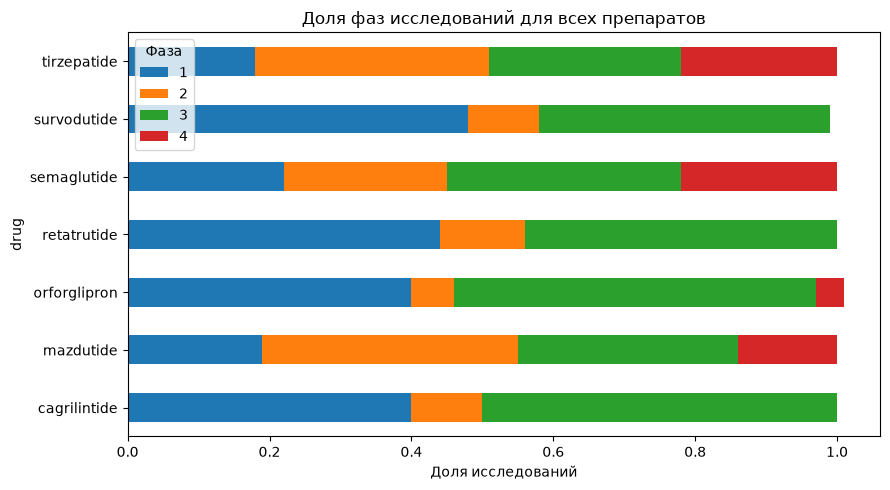

In [66]:
tab.plot(kind="barh", stacked=True, figsize=(9, 5))
plt.xlabel("Доля исследований")
plt.title("Доля фаз исследований для всех препаратов")  # вывод
plt.legend(title="Фаза")
plt.tight_layout()
plt.savefig("../figures/04_phases_by_drug.png", dpi=200, bbox_inches="tight")

Фаза 4 (применение после выхода на рынок) занимает по 22% у semaglutide и tirzepatide. У остальных пяти она не превышает 14%. Среди новых молекул самые высокие доли фазы 3 у orforglipron (51%) и cagrilintide (50%). У survodutide и retatrutide почти половина исследований пока в фазе 1 (48% и 44%).

В общем, у новых молекул преобладают фазы 1 и 3.

In [68]:
print(d["sponsor"].value_counts().head(10))
print()
print(d.groupby("drug")["sponsor"].agg(lambda s: s.value_counts().head(2).to_dict()))

sponsor
Novo Nordisk A/S                        300
Eli Lilly and Company                   178
Boehringer Ingelheim                     34
Brigham and Women's Hospital             29
Innovent Biologics (Suzhou) Co. Ltd.     23
University of Colorado, Denver           14
The Cleveland Clinic                     12
Mayo Clinic                              10
Vanderbilt University Medical Center      8
University Medical Centre Ljubljana       8
Name: count, dtype: int64

drug
cagrilintide                             {'Novo Nordisk A/S': 42}
mazdutide       {'Innovent Biologics (Suzhou) Co. Ltd.': 19, '...
orforglipron    {'Eli Lilly and Company': 49, 'Massachusetts G...
retatrutide     {'Eli Lilly and Company': 31, 'Hudson Biotech'...
semaglutide     {'Novo Nordisk A/S': 252, 'Brigham and Women's...
survodutide     {'Boehringer Ingelheim': 28, 'University Medic...
tirzepatide     {'Eli Lilly and Company': 81, 'Brigham and Wom...
Name: sponsor, dtype: object


In [69]:
top = d.groupby("drug")["sponsor"].agg(
    lead=lambda s: s.value_counts().index[0],
    lead_n=lambda s: s.value_counts().iloc[0],
    n="size",
)
top["lead_share"] = (top["lead_n"] / top["n"]).round(2)
print(top)

                                              lead  lead_n    n  lead_share
drug                                                                       
cagrilintide                      Novo Nordisk A/S      42   42        1.00
mazdutide     Innovent Biologics (Suzhou) Co. Ltd.      19   44        0.43
orforglipron                 Eli Lilly and Company      49   53        0.92
retatrutide                  Eli Lilly and Company      31   32        0.97
semaglutide                       Novo Nordisk A/S     252  759        0.33
survodutide                   Boehringer Ingelheim      28   29        0.97
tirzepatide                  Eli Lilly and Company      81  296        0.27


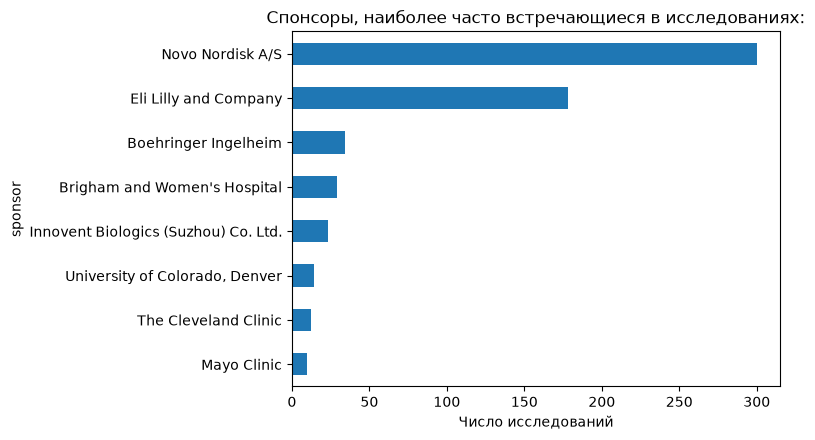

In [71]:
top8 = d["sponsor"].value_counts().head(8).sort_values()
top8.plot(kind="barh", figsize=(8, 4.5))
plt.xlabel("Число исследований")
plt.title("Спонсоры, наиболее часто встречающиеся в исследованиях:")  # вывод
plt.tight_layout()
plt.savefig("../figures/05_top_sponsors.png", dpi=200, bbox_inches="tight")

Новые молекулы почти целиком принадлежат разработчикам: cagrilintide 100% у Novo Nordisk, retatrutide 97% и orforglipron 92% у Eli Lilly, survodutide 97% у Boehringer Ingelheim. У mazdutide Innovent ведёт 43% исследований, значит в программе много других организаций. У зрелых препаратов доля ведущей компании ниже: semaglutide 33% (252 из 759), tirzepatide 27% (81 из 296). Остальное в основном академические и клинические центры, которые запускают собственные исследования, когда препарат уже доступен.